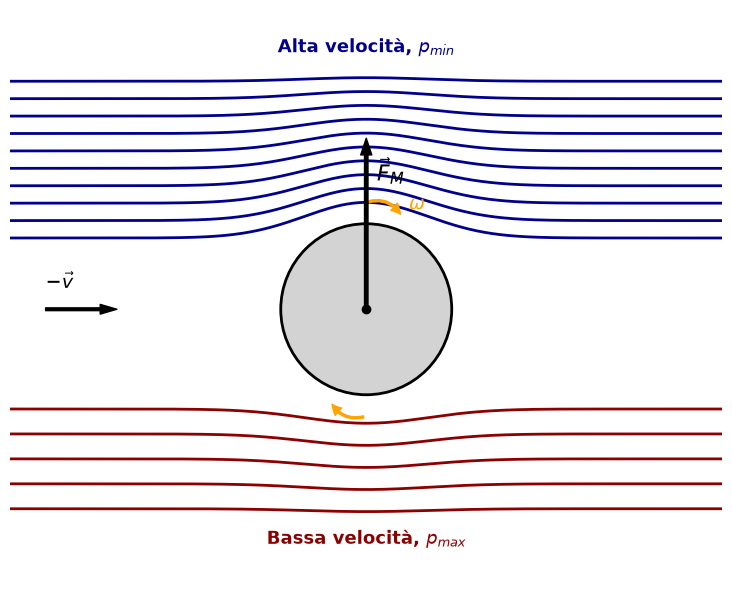

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch

# ==========================================
# GRAFICO: EFFETTO MAGNUS STILIZZATO (PARAMETRICO)
# ==========================================
fig, ax = plt.subplots(figsize=(12, 6))

# Parametri del corpo cilindrico/sferico
R = 1.2
cylinder = Circle((0, 0), R, edgecolor='black', facecolor='lightgray', linewidth=2, zorder=3)
ax.add_patch(cylinder)
ax.plot(0, 0, 'ko', zorder=4)

x = np.linspace(-5, 5, 500)

# ==========================================
# PARAMETRI PER IL NUMERO DI LINEE DI FLUSSO
# ==========================================
num_linee_sup = 10  # Cambia questo valore per aumentare/diminuire le linee blu (sopra)
num_linee_inf = 4  # Cambia questo valore per aumentare/diminuire le linee rosse (sotto)

# Calcolo e tracciamento delle linee superiori (addensate) in darkblue
y_sup_base = np.linspace(1, 3.2, num_linee_sup)
for i, y_base in enumerate(y_sup_base):
    # L'ampiezza della deviazione gaussiana diminuisce allontanandosi dal cilindro
    ampiezza = 0.5 * (1 - i / num_linee_sup) 
    ax.plot(x, y_base + ampiezza * np.exp(-x**2/1.5), color='darkblue', lw=2, zorder=2)

# Calcolo e tracciamento delle linee inferiori (rarefatte) in darkred
y_inf_base = np.linspace(-1.4, -2.8, num_linee_inf)
for i, y_base in enumerate(y_inf_base):
    # L'ampiezza della deviazione verso il basso
    ampiezza = -0.2 * (1 - i / num_linee_inf)
    ax.plot(x, y_base + ampiezza * np.exp(-x**2/1.5), color='darkred', lw=2, zorder=2)

# ==========================================
# ANNOTAZIONI
# ==========================================
# (Nota: uso r'' per le stringhe con \v o \o per evitare errori di escape in Python)

# Forza di Magnus
ax.annotate('', xy=(0, R + 1.2), xytext=(0, 0),
            arrowprops=dict(facecolor='black', edgecolor='black', width=2.5, headwidth=8), zorder=5)
ax.text(0.15, R + 0.6, r'$\vec{F}_M$', fontsize=16, color='black', weight='bold')

# Velocità vento
ax.annotate('', xy=(-3.5, 0), xytext=(-4.5, 0),
            arrowprops=dict(facecolor='black', edgecolor='black', width=2, headwidth=7))
ax.text(-4.5, 0.3, r'$-\vec{v}$', fontsize=14, color='black')

# Rotazione (omega)
style = "Simple, tail_width=1.5, head_width=7, head_length=7"
kw = dict(arrowstyle=style, color="orange")
arrow_rot1 = FancyArrowPatch((0, R + 0.3), (0.5, R + 0.1), connectionstyle="arc3,rad=-0.4", **kw, zorder=4)
arrow_rot2 = FancyArrowPatch((0, -R - 0.3), (-0.5, -R - 0.1), connectionstyle="arc3,rad=-0.4", **kw, zorder=4)
ax.add_patch(arrow_rot1)
ax.add_patch(arrow_rot2)
ax.text(0.6, R + 0.2, r'$\omega$', fontsize=14, color='orange', weight='bold')

# Etichette di pressione (posizionate in modo dinamico oltre l'ultima linea tracciata)
ax.text(0, y_sup_base[-1] + 0.4, r'Alta velocità, $p_{min}$', fontsize=13, ha='center', color='darkblue', weight='bold')
ax.text(0, y_inf_base[-1] - 0.5, r'Bassa velocità, $p_{max}$', fontsize=13, ha='center', color='darkred', weight='bold')

# Limiti assi e pulizia
ax.set_xlim(-5, 5)
# Adatta automaticamente i limiti dell'asse y in base al numero di linee create
ax.set_ylim(y_inf_base[-1] - 1, y_sup_base[-1] + 1)
ax.set_aspect('equal', adjustable='box')
ax.axis('off')

plt.tight_layout()
plt.savefig('../../Appunti/img/effetto_magnus.png', dpi=300, bbox_inches='tight')
plt.show()